# Análisis resultados CAMEL

In [52]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="white")
sns.set_context("paper")

In [53]:
data_dir = Path().resolve().parent / "data" / "camel"
filepath = data_dir / "Calificaciones_CAMEL.csv"
df=pd.read_csv(filepath)
df.rename(columns={'categoria': 'Categoría'}, inplace=True)
df['Categoría'] = pd.Categorical(
    df['Categoría'], 
    categories=['Micro 1', 'Micro 2', 'Pequeñas', 'Medianas', 'Grandes', 'Megas'], 
    ordered=True
    )
indicadores = df.select_dtypes(include=['int64']).columns.tolist()    
for indicador in indicadores:
    df[indicador] = pd.Categorical(df[indicador], ordered=True)
df.head()

,ID_cooperativa,Activo Productivo,Estructura de Balance,Indicador de Cobertura de la Cartera Total en Riesgo,Indicador de Cobertura individual de la cartera improductiva para la cartera en Riesgo,Indicador de Margen Financiero de Operación,Indicador de Margen Operacional,Indicador de Riesgo de Liquidez - IRL,Indicador de calidad por riesgo,Indicador de calidad por riesgo con castigos,Indicador de margen neto,Indicador de relación entre las obligaciones financieras y el pasivo total,Indicador de rentabilidad sobre el capital invertido - ROIC,Indicador de rentabilidad sobre recursos propios - ROE,Quebranto Patrimonial,Relación entre Aportes sociales mínimos no reducibles y Capital Social,Relación entre el Capital Institucional y el Activo Total,CAMEL_score_ponderado,CAMEL_score_sin_ponderar,Categoría
0,AVANCOP COOPERATIVA DE AHORRO Y CREDITO,4,4,1,3,2,3,3,2,2,3,2,3,3,3,3,3,2.728621,2.709385,Micro 1
1,CAJA COOPERATIVA CREDICOOP,4,4,1,4,2,5,5,1,1,1,2,1,1,3,5,4,2.643413,2.624778,Medianas
2,CAJA COOPERATIVA PETROLERA,4,4,1,5,3,5,3,1,1,2,1,2,2,4,5,4,2.699722,2.539826,Megas
3,CASA NACIONAL DEL PROFESOR,5,3,4,5,4,3,2,4,4,2,1,2,2,2,4,2,2.874545,2.748705,Megas
4,CESCA COOPERATIVA DE AHORRO Y CREDITO,2,5,2,5,2,1,5,2,2,5,5,4,3,2,2,2,3.248975,3.398776,Pequeñas


In [54]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 174 entries, 0 to 173
Data columns (total 20 columns):
 #   Column                                                                                  Non-Null Count  Dtype   
---  ------                                                                                  --------------  -----   
 0   ID_cooperativa                                                                          174 non-null    object  
 1   Activo Productivo                                                                       174 non-null    category
 2   Estructura de Balance                                                                   174 non-null    category
 3   Indicador de Cobertura de la Cartera Total en Riesgo                                    174 non-null    category
 4   Indicador de Cobertura individual de la cartera improductiva para la cartera en Riesgo  174 non-null    category
 5   Indicador de Margen Financiero de Operación                     

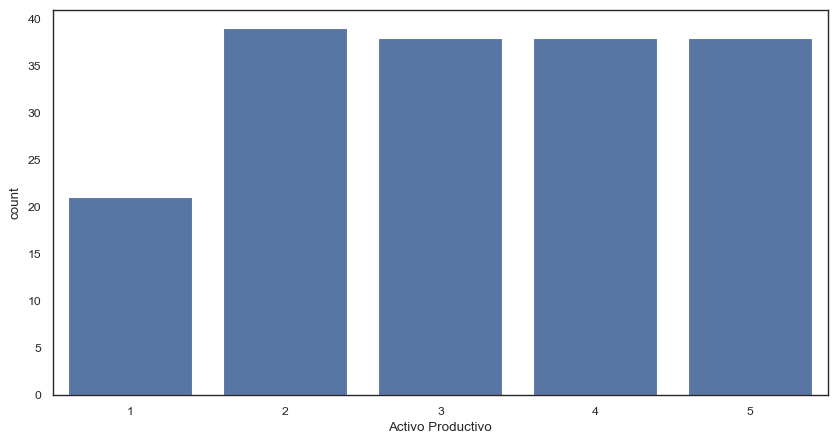

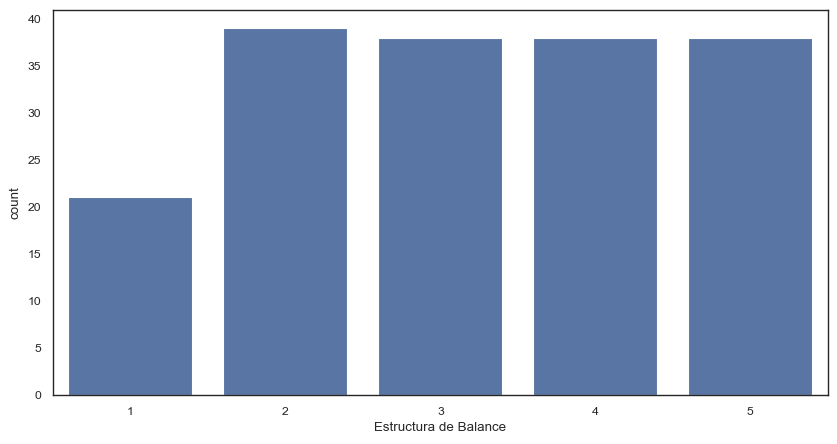

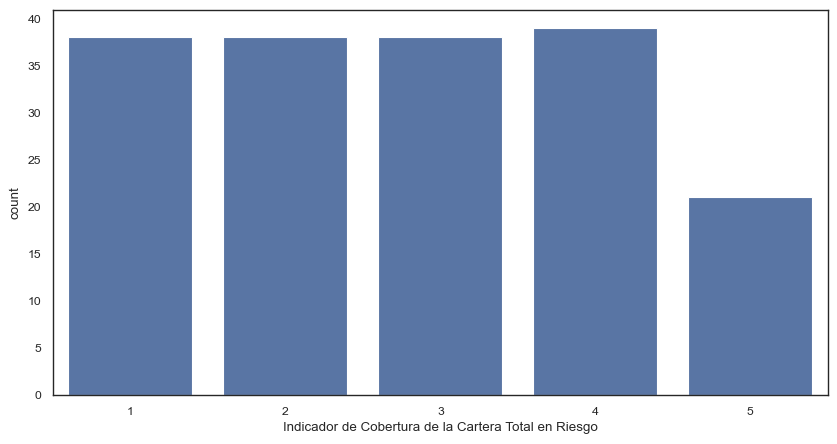

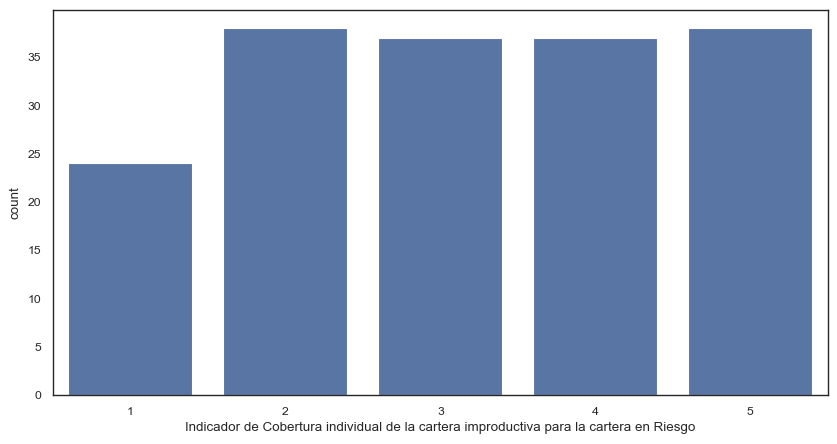

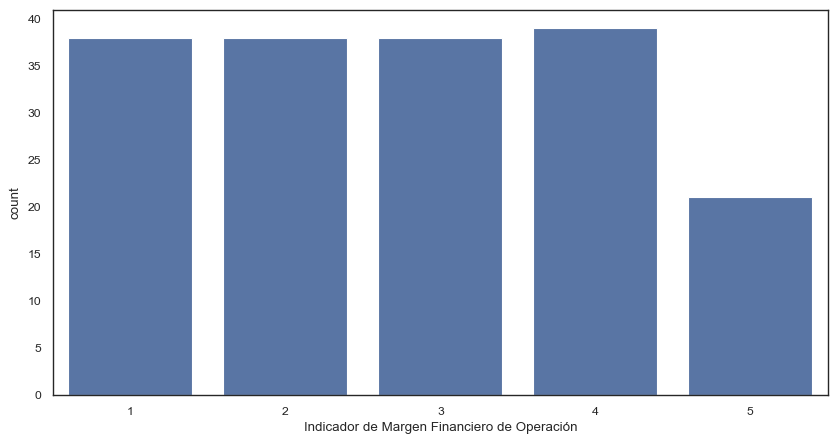

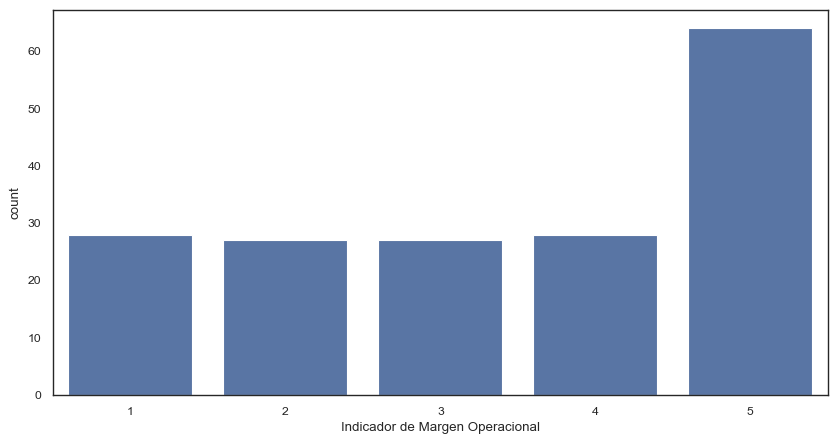

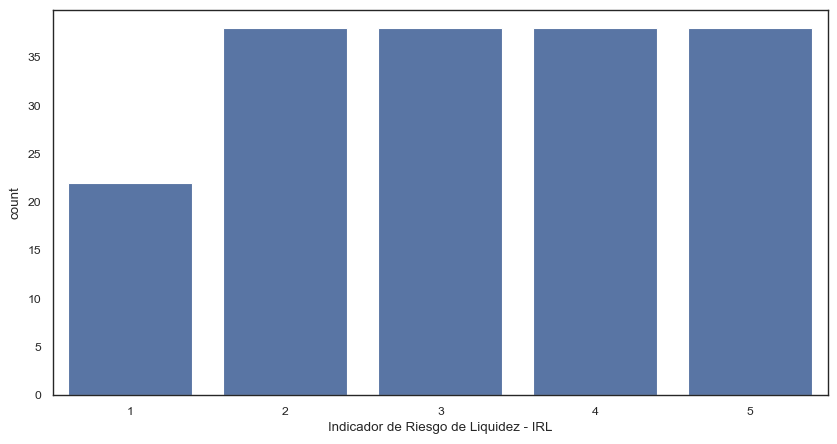

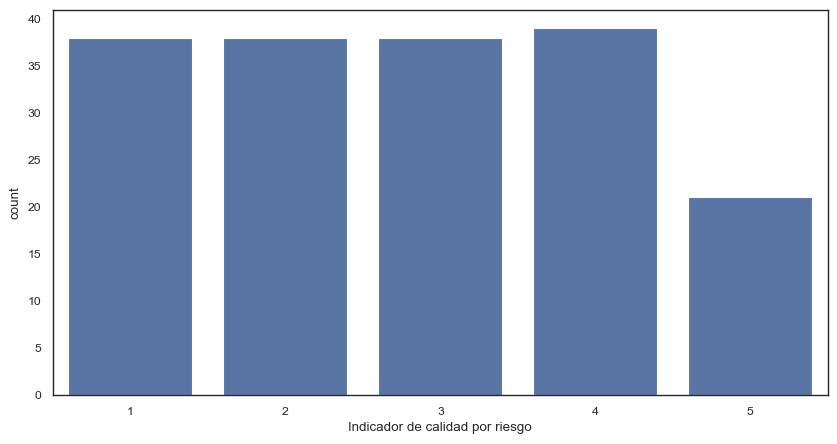

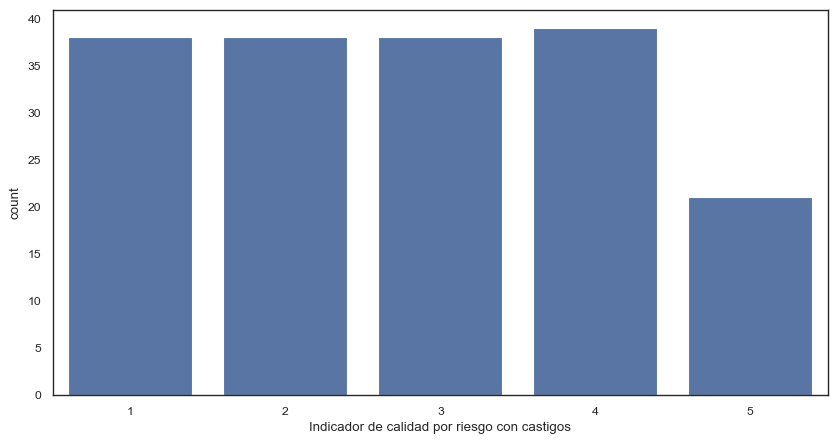

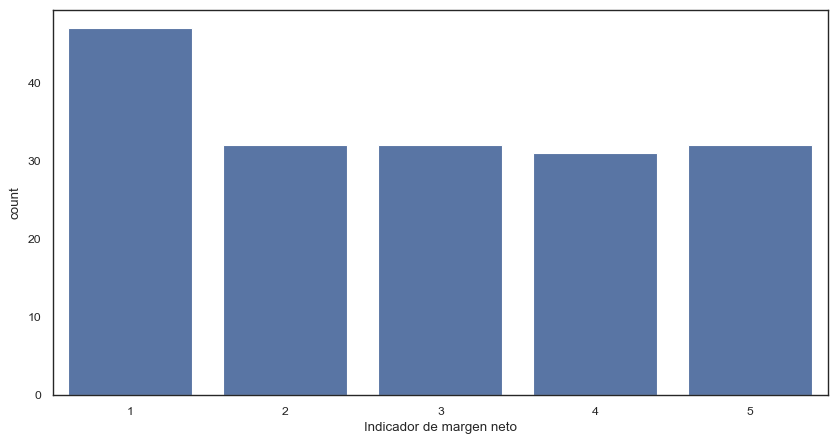

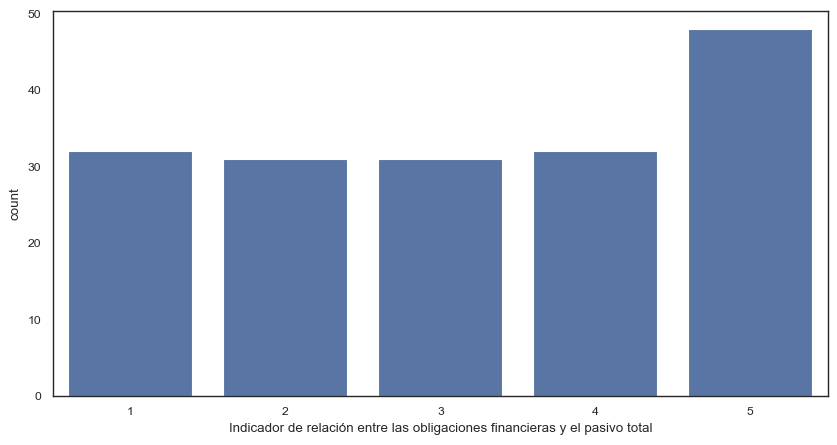

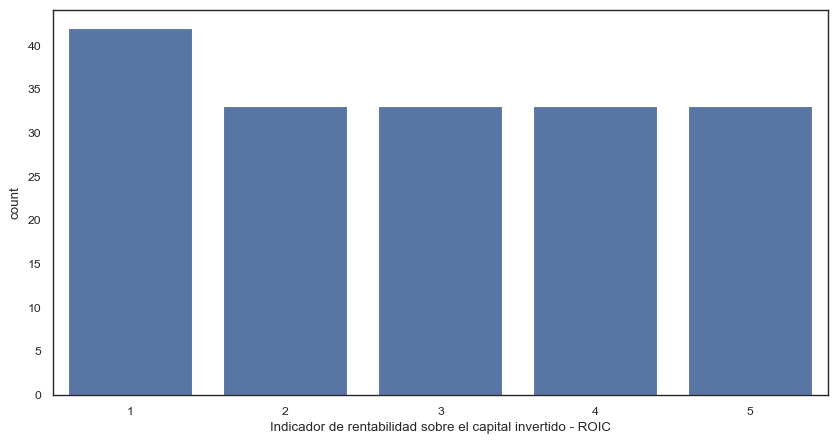

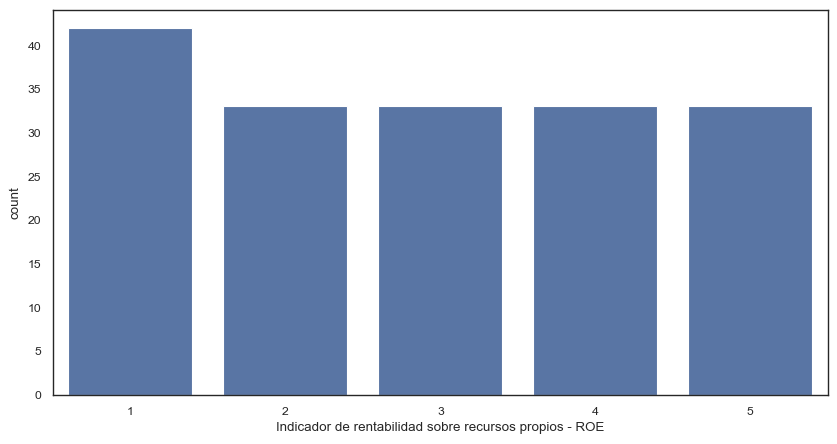

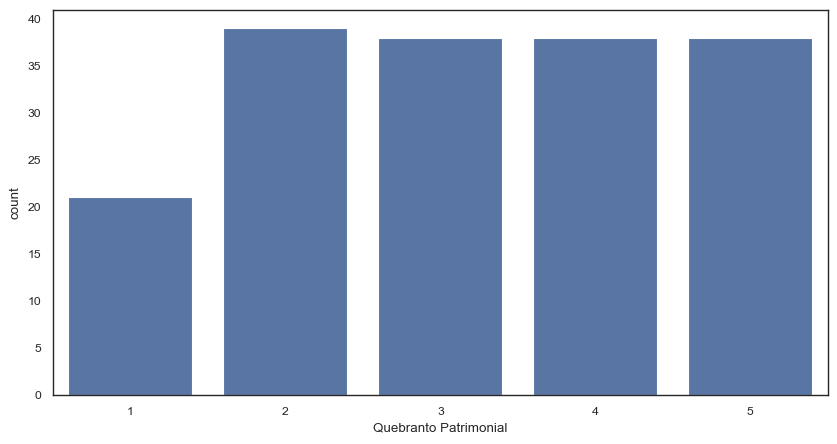

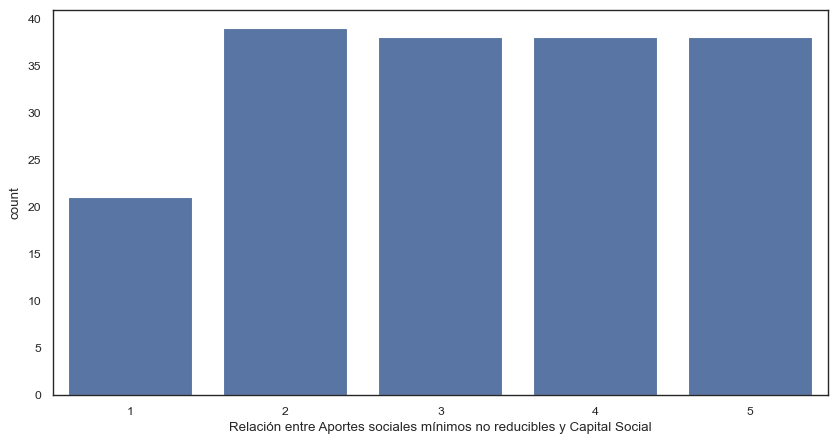

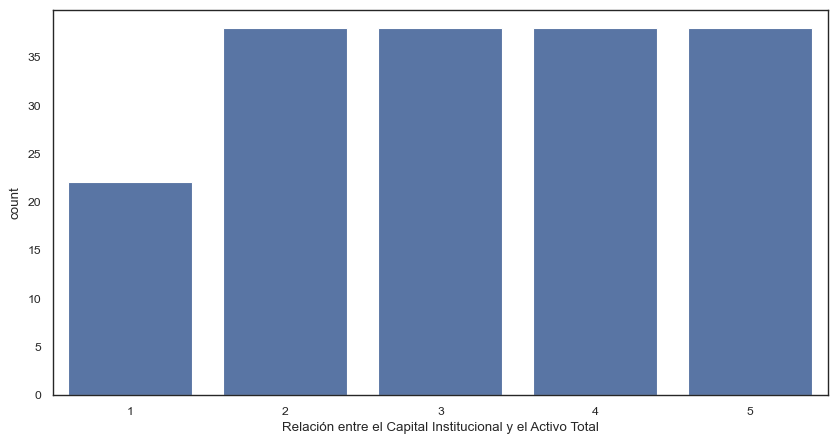

In [55]:
for indicador in indicadores:
    plt.figure(figsize=(10, 5))
    sns.countplot(data=df, x=indicador)
    plt.show()

<Figure size 1000x500 with 0 Axes>

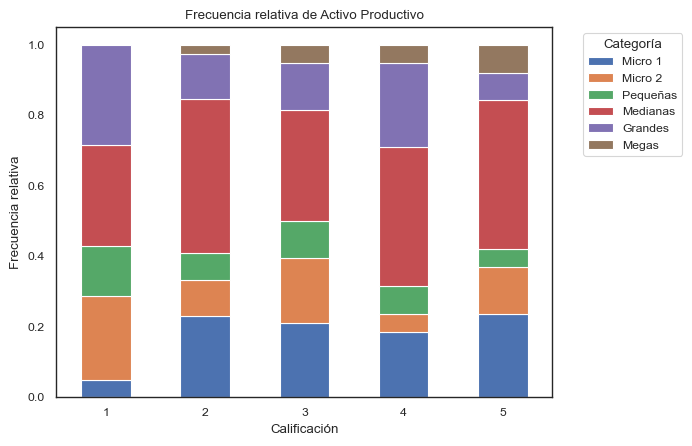

<Figure size 1000x500 with 0 Axes>

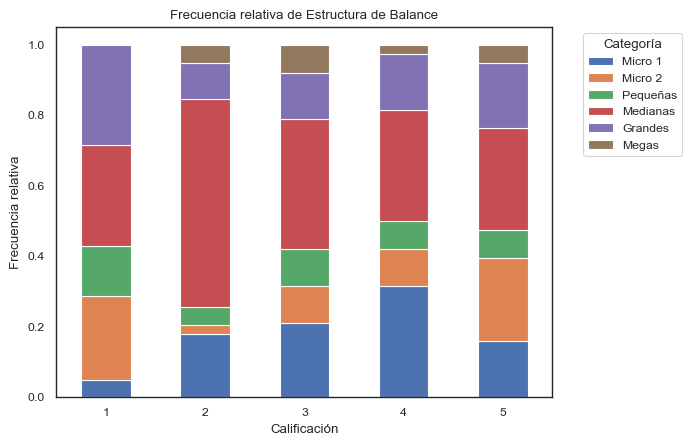

<Figure size 1000x500 with 0 Axes>

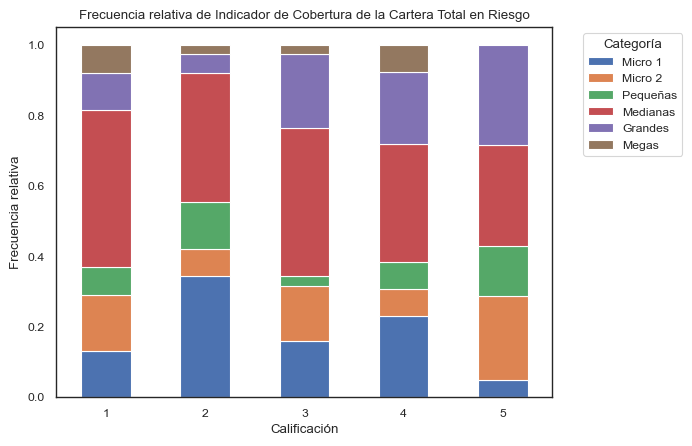

<Figure size 1000x500 with 0 Axes>

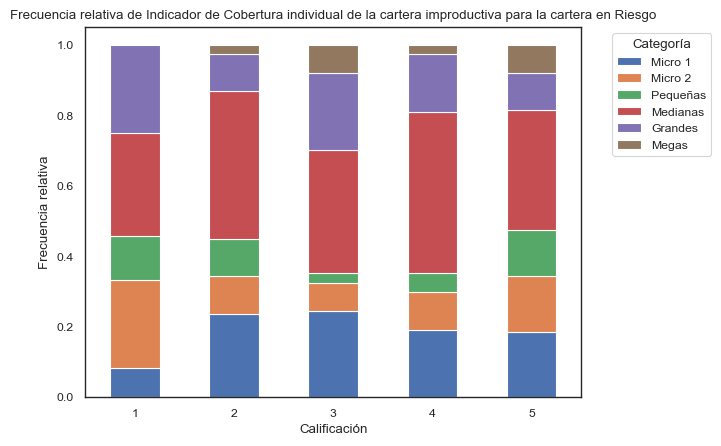

<Figure size 1000x500 with 0 Axes>

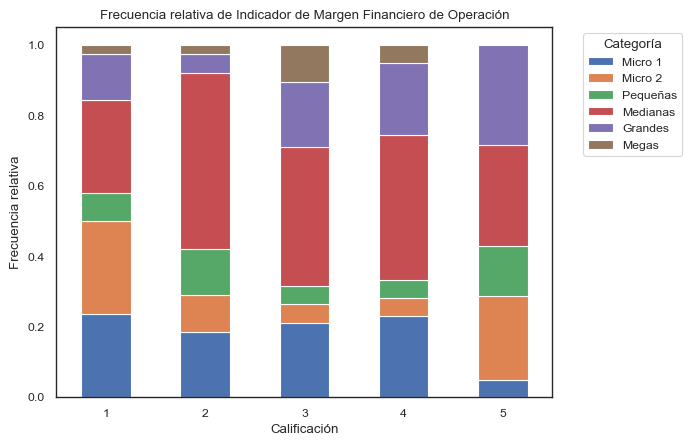

<Figure size 1000x500 with 0 Axes>

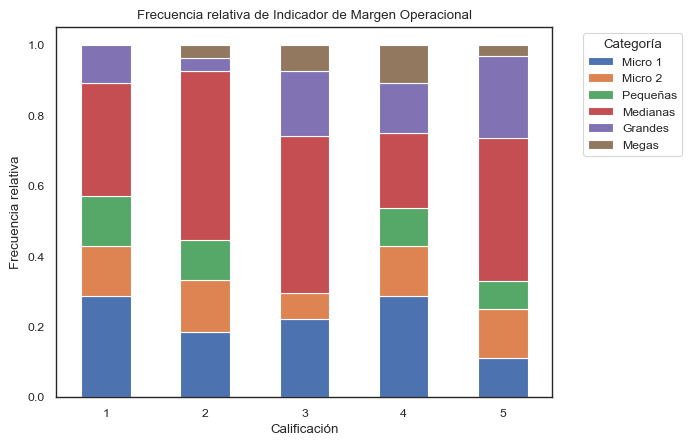

<Figure size 1000x500 with 0 Axes>

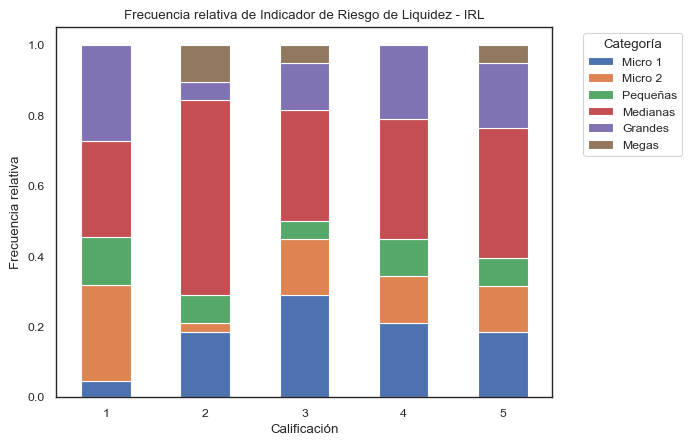

<Figure size 1000x500 with 0 Axes>

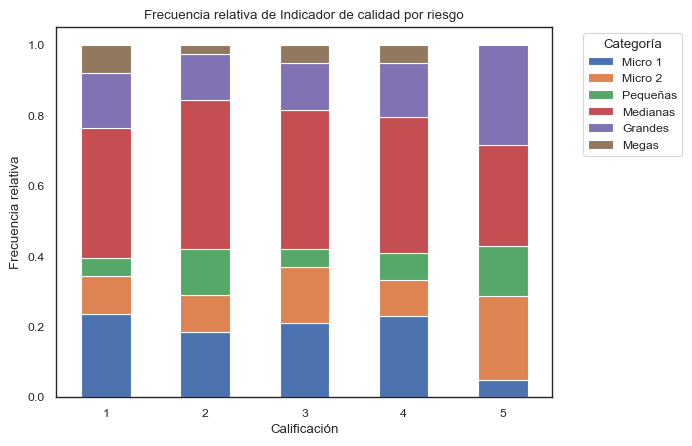

<Figure size 1000x500 with 0 Axes>

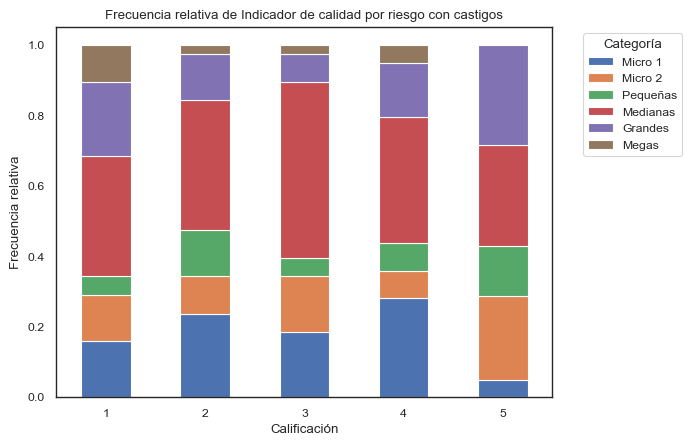

<Figure size 1000x500 with 0 Axes>

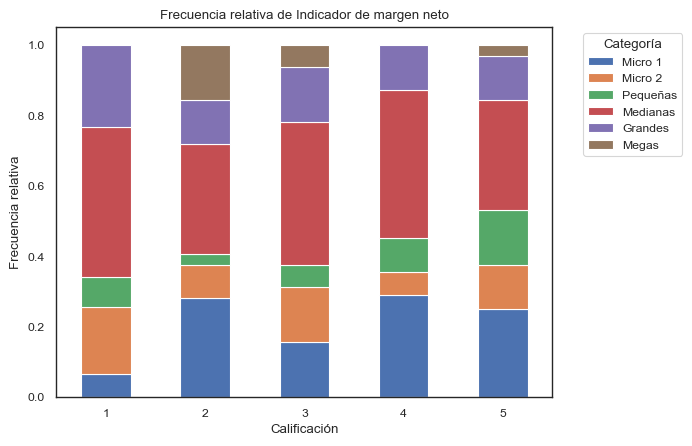

<Figure size 1000x500 with 0 Axes>

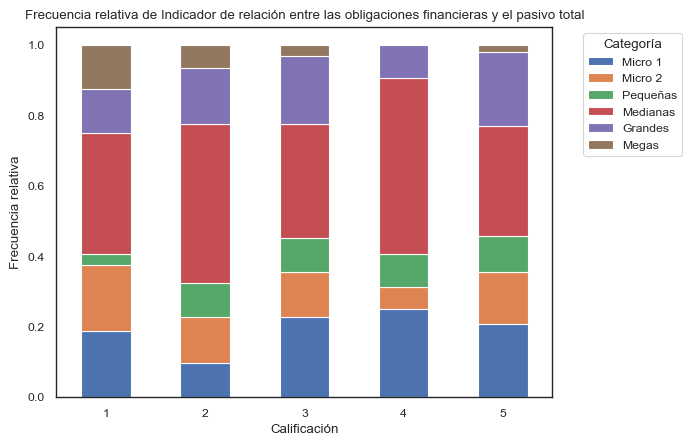

<Figure size 1000x500 with 0 Axes>

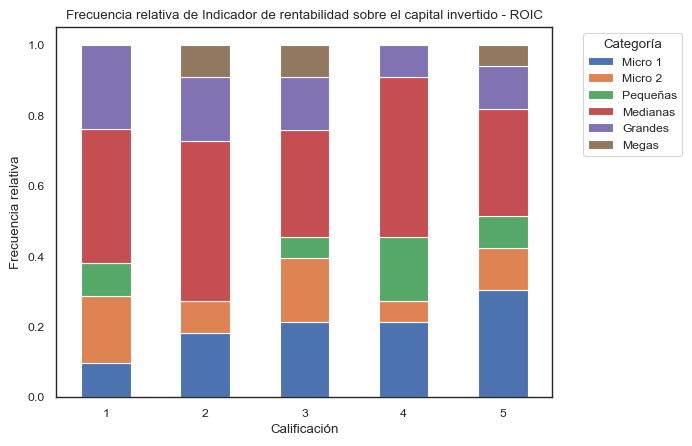

<Figure size 1000x500 with 0 Axes>

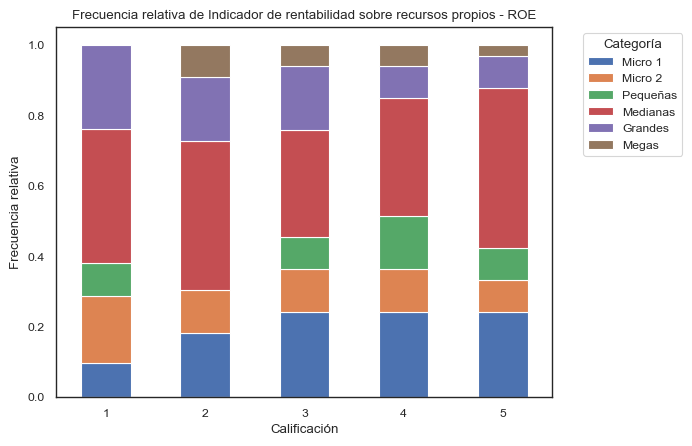

<Figure size 1000x500 with 0 Axes>

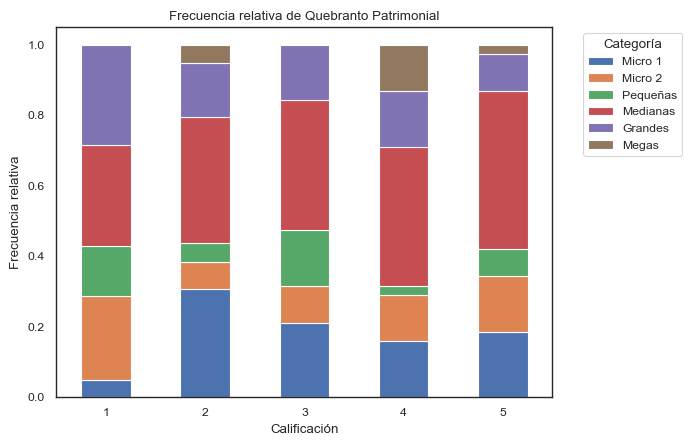

<Figure size 1000x500 with 0 Axes>

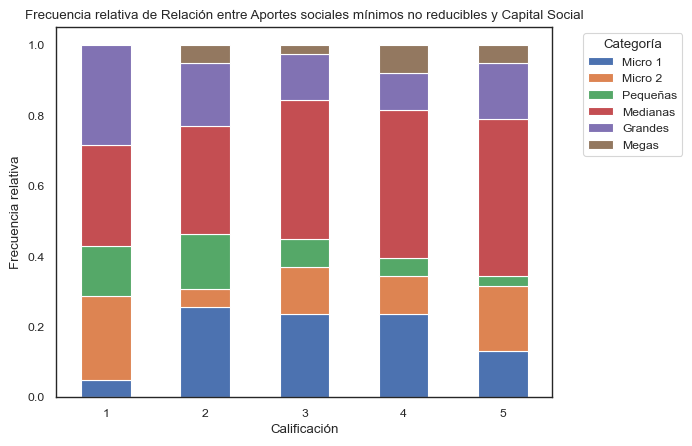

<Figure size 1000x500 with 0 Axes>

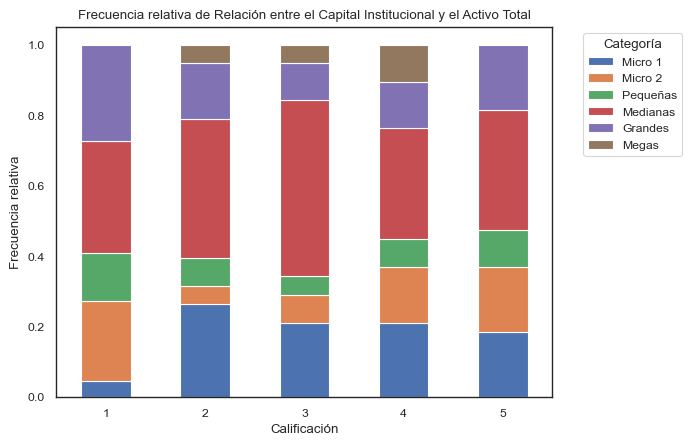

In [56]:
for indicador in indicadores:
    tabla_contingencia = pd.crosstab(df[indicador], df['Categoría'], normalize='index')
    plt.figure(figsize=(10, 5))
    tabla_contingencia.plot(kind='bar', stacked=True)
    plt.title(f'Frecuencia relativa de {indicador}')
    plt.xlabel('Calificación')
    plt.xticks(rotation=0)
    plt.ylabel('Frecuencia relativa')
    plt.legend(title='Categoría', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.show()

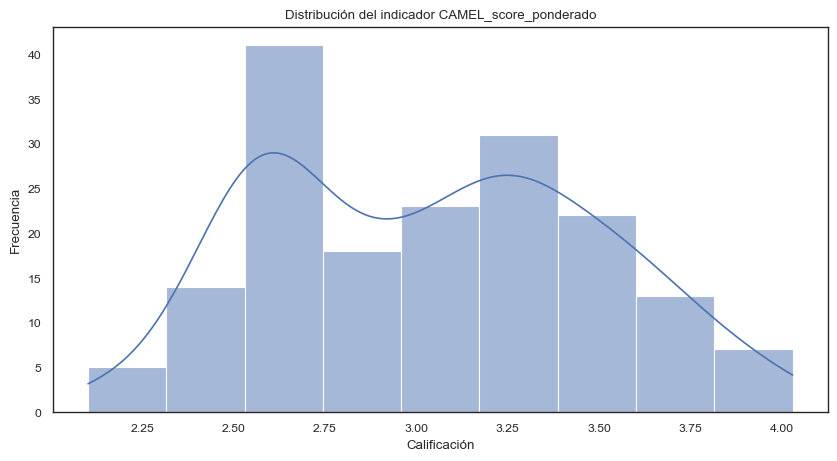

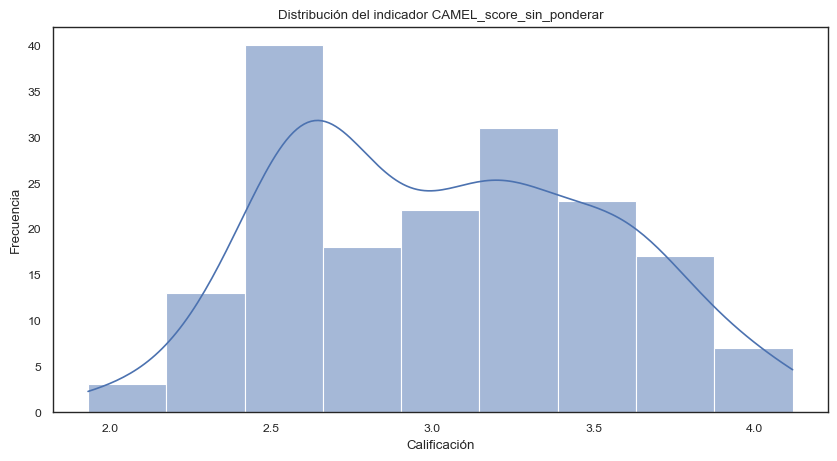

In [57]:
camels = df.select_dtypes(include=['float64']).columns.to_list()

for camel in camels:
    plt.figure(figsize=(10, 5))
    sns.histplot(df[camel], kde=True, bins='sturges')
    plt.title(f'Distribución del indicador {camel}')
    plt.xlabel('Calificación')
    plt.ylabel('Frecuencia')
    plt.show();

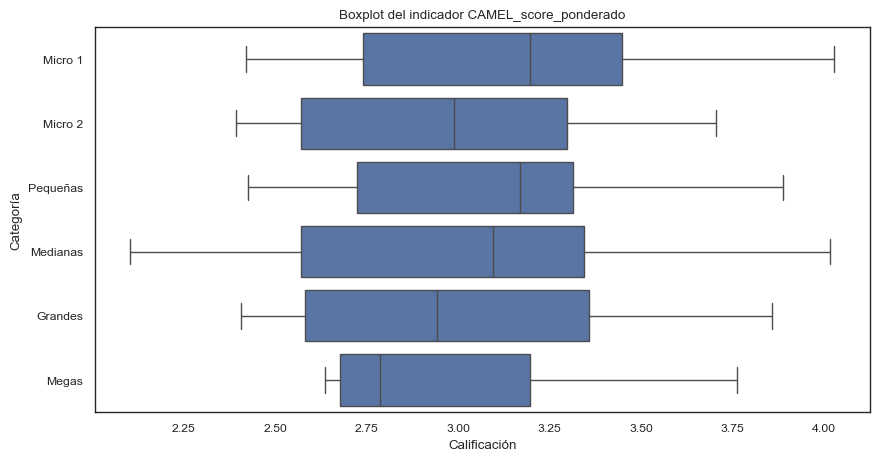

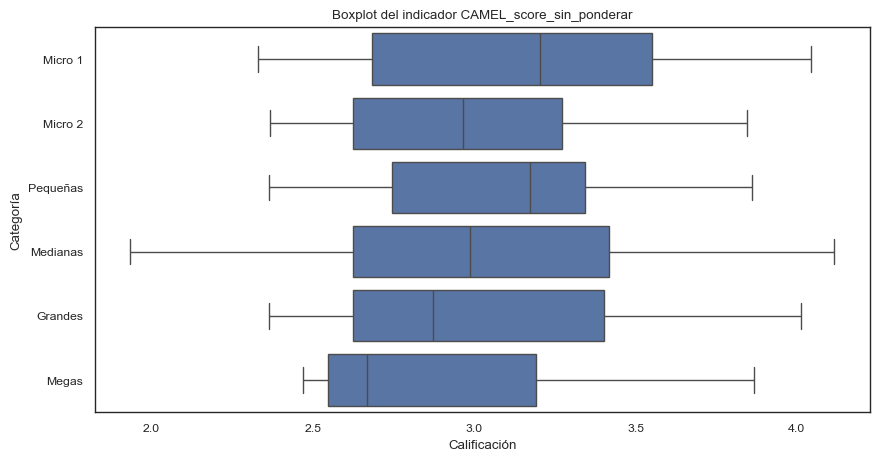

In [58]:
for camel in camels:
    plt.figure(figsize=(10, 5))
    sns.boxplot(
        x=df[camel],
        y=df['Categoría'],
        )
    plt.title(f'Boxplot del indicador {camel}')
    plt.xlabel('Calificación')
    plt.show();

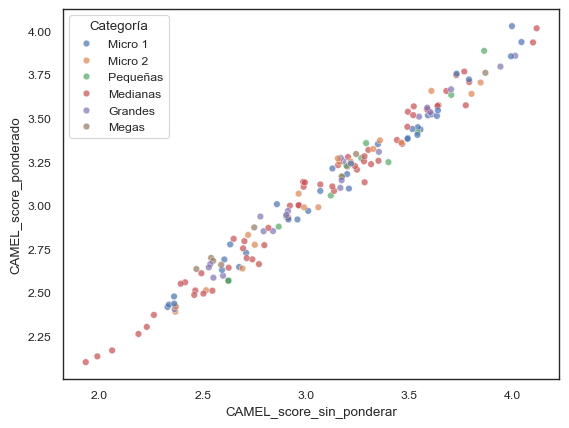

In [59]:
sns.scatterplot(
    data=df, 
    x='CAMEL_score_sin_ponderar', 
    y='CAMEL_score_ponderado',
    hue='Categoría', 
    alpha=0.7);

In [60]:
from sklearn.preprocessing import KBinsDiscretizer

kbd = KBinsDiscretizer(
    n_bins=4, 
    encode='ordinal', 
    strategy='kmeans',
    )

kbd.fit(df[['CAMEL_score_ponderado']])
df['CAMEL_score_ponderado_grupos'] = kbd.transform(df[['CAMEL_score_ponderado']])
df['CAMEL_score_ponderado_grupos'] = (1+df['CAMEL_score_ponderado_grupos']).astype(int)
df['CAMEL_score_ponderado_grupos'] = df['CAMEL_score_ponderado_grupos'].astype('category')
df.head()

,ID_cooperativa,Activo Productivo,Estructura de Balance,Indicador de Cobertura de la Cartera Total en Riesgo,Indicador de Cobertura individual de la cartera improductiva para la cartera en Riesgo,Indicador de Margen Financiero de Operación,Indicador de Margen Operacional,Indicador de Riesgo de Liquidez - IRL,Indicador de calidad por riesgo,Indicador de calidad por riesgo con castigos,...,Indicador de relación entre las obligaciones financieras y el pasivo total,Indicador de rentabilidad sobre el capital invertido - ROIC,Indicador de rentabilidad sobre recursos propios - ROE,Quebranto Patrimonial,Relación entre Aportes sociales mínimos no reducibles y Capital Social,Relación entre el Capital Institucional y el Activo Total,CAMEL_score_ponderado,CAMEL_score_sin_ponderar,Categoría,CAMEL_score_ponderado_grupos
0,AVANCOP COOPERATIVA DE AHORRO Y CREDITO,4,4,1,3,2,3,3,2,2,...,2,3,3,3,3,3,2.728621,2.709385,Micro 1,2
1,CAJA COOPERATIVA CREDICOOP,4,4,1,4,2,5,5,1,1,...,2,1,1,3,5,4,2.643413,2.624778,Medianas,1
2,CAJA COOPERATIVA PETROLERA,4,4,1,5,3,5,3,1,1,...,1,2,2,4,5,4,2.699722,2.539826,Megas,1
3,CASA NACIONAL DEL PROFESOR,5,3,4,5,4,3,2,4,4,...,1,2,2,2,4,2,2.874545,2.748705,Megas,2
4,CESCA COOPERATIVA DE AHORRO Y CREDITO,2,5,2,5,2,1,5,2,2,...,5,4,3,2,2,2,3.248975,3.398776,Pequeñas,3


In [61]:
umbrales = kbd.bin_edges_[0]
print(f'Los umbrales de los grupos son: {umbrales}')

Los umbrales de los grupos son: [2.10212651 2.71840348 3.08203038 3.47118863 4.02884055]


In [62]:
df['CAMEL_score_ponderado_grupos'] = pd.Categorical(
    df['CAMEL_score_ponderado_grupos'],
    ordered=True
    )

df['CAMEL_score_ponderado_grupos'].value_counts(normalize=False, sort=False)

CAMEL_score_ponderado_grupos
1    59
2    29
3    51
4    35
Name: count, dtype: int64

<Figure size 1000x500 with 0 Axes>

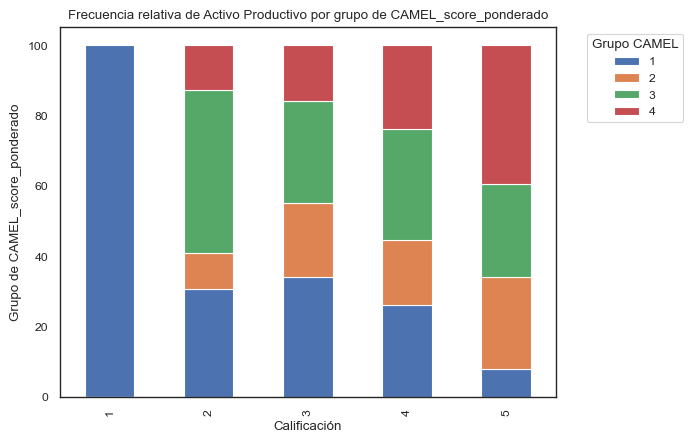

<Figure size 1000x500 with 0 Axes>

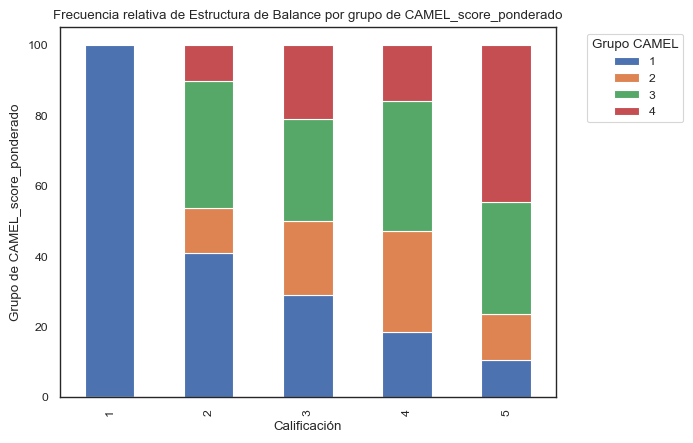

<Figure size 1000x500 with 0 Axes>

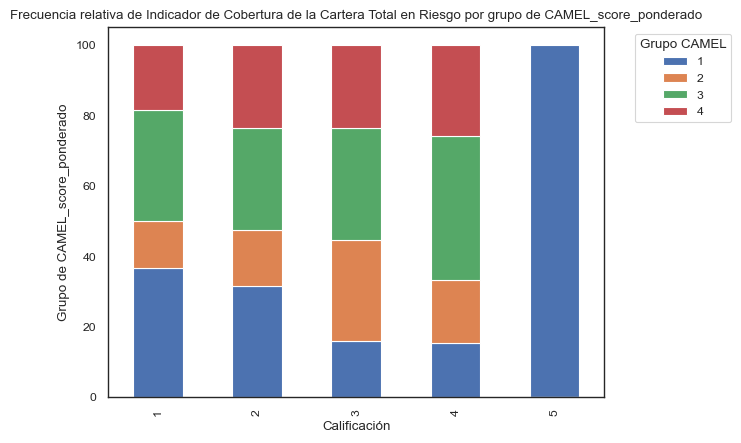

<Figure size 1000x500 with 0 Axes>

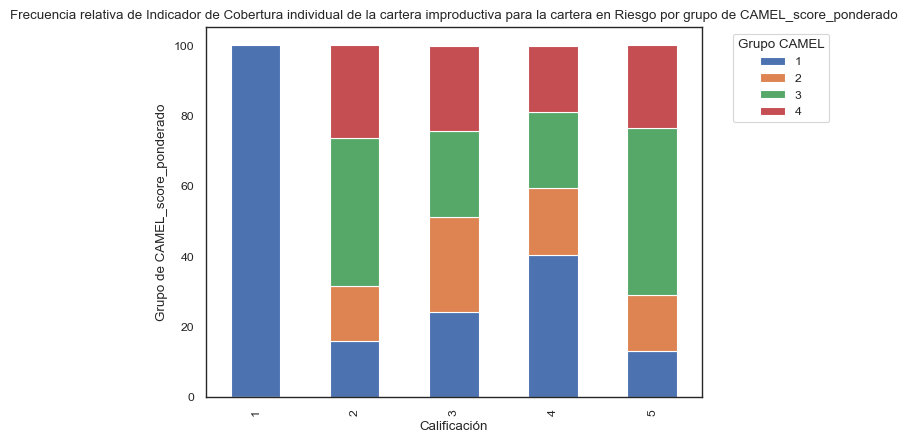

<Figure size 1000x500 with 0 Axes>

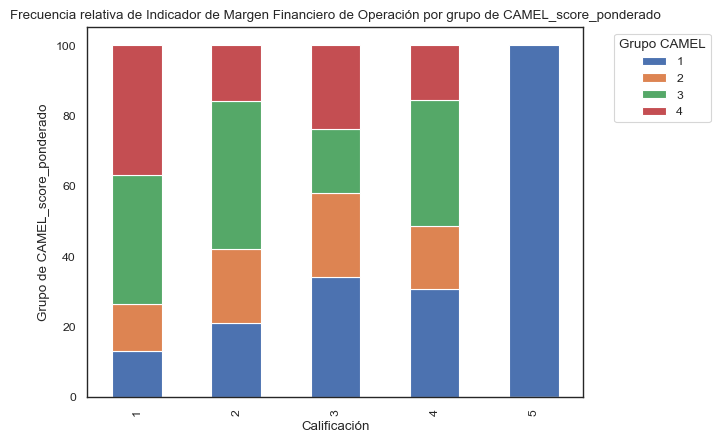

<Figure size 1000x500 with 0 Axes>

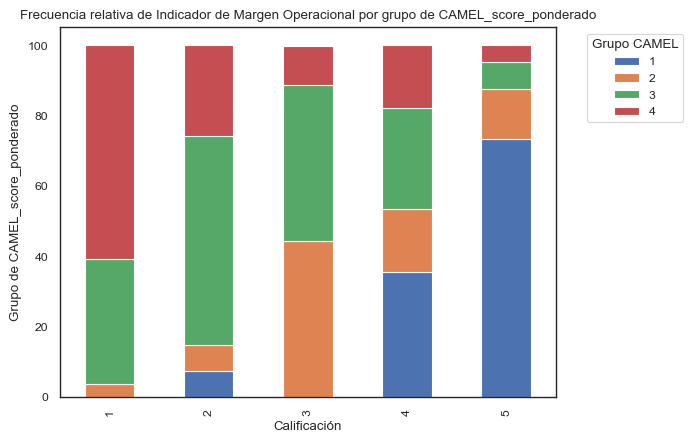

<Figure size 1000x500 with 0 Axes>

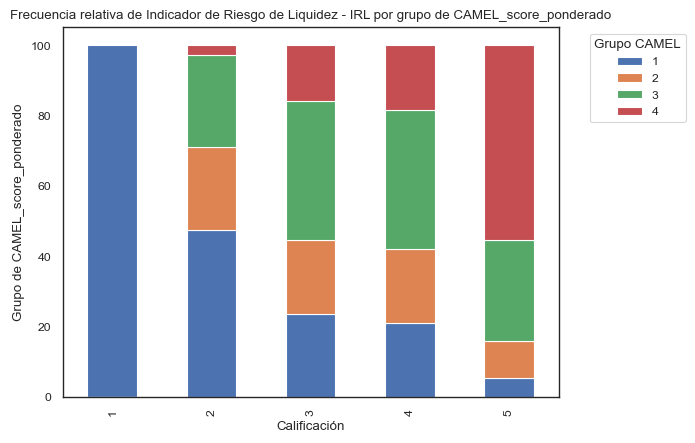

<Figure size 1000x500 with 0 Axes>

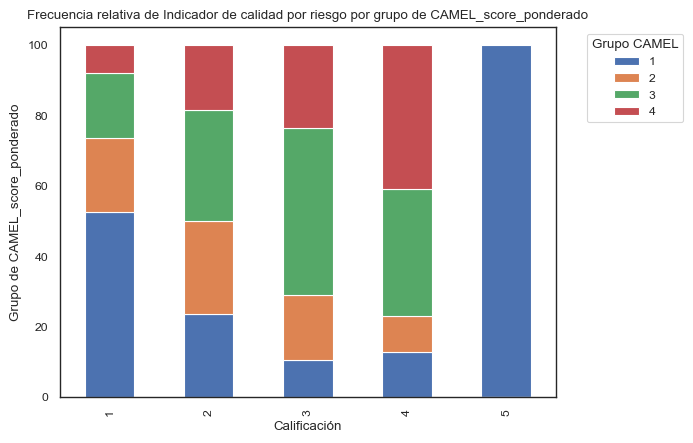

<Figure size 1000x500 with 0 Axes>

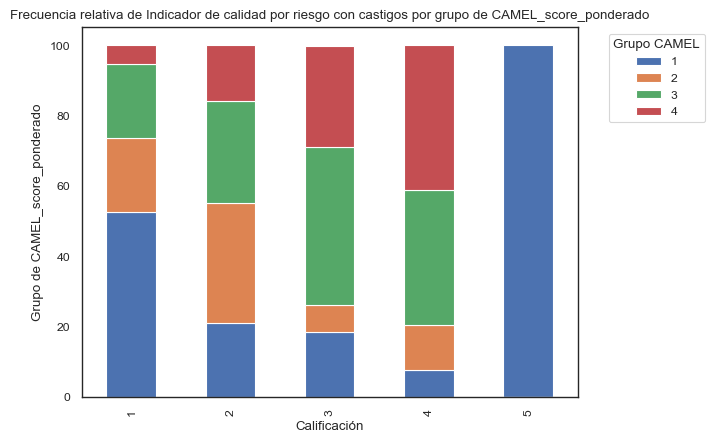

<Figure size 1000x500 with 0 Axes>

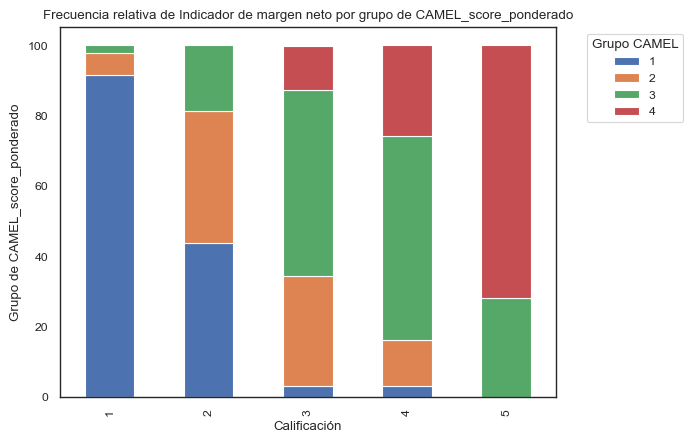

<Figure size 1000x500 with 0 Axes>

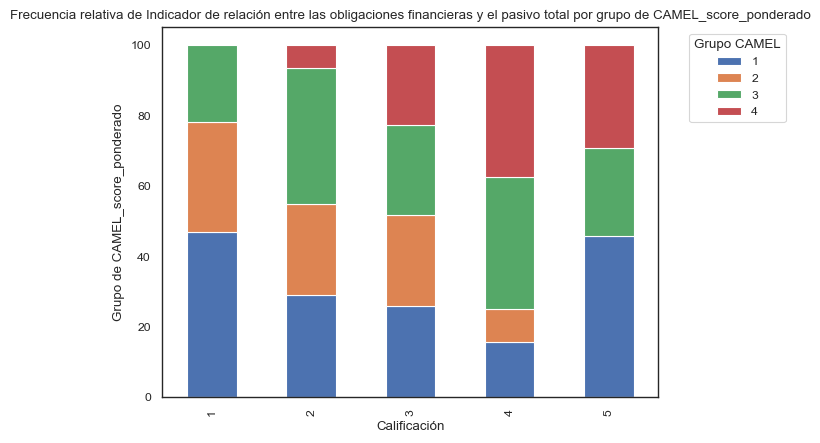

<Figure size 1000x500 with 0 Axes>

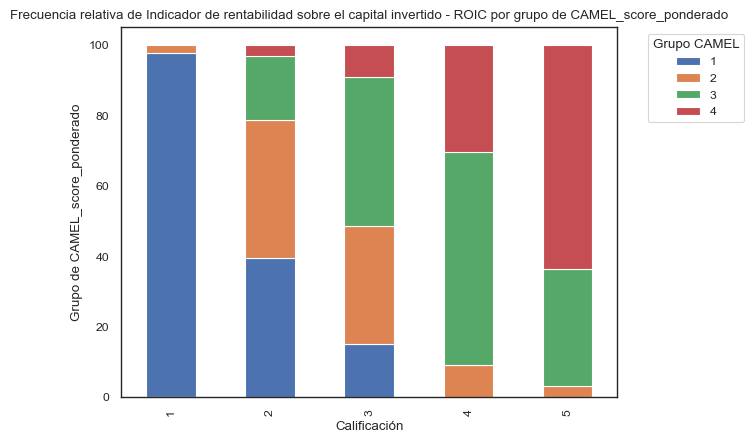

<Figure size 1000x500 with 0 Axes>

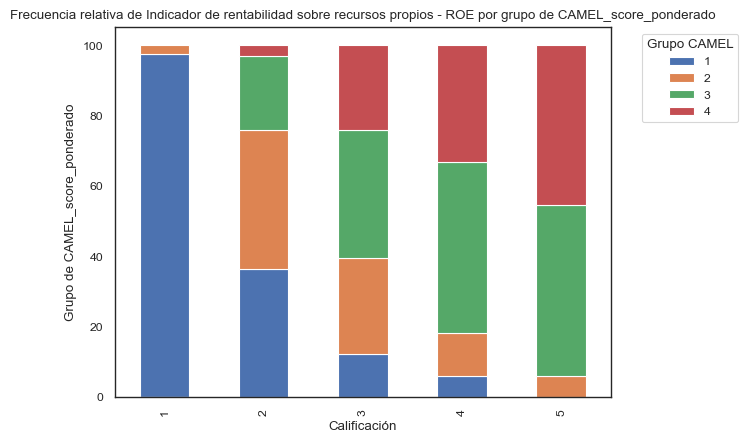

<Figure size 1000x500 with 0 Axes>

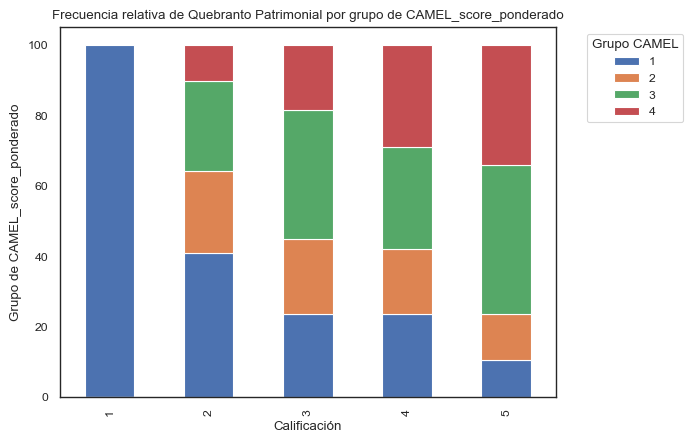

<Figure size 1000x500 with 0 Axes>

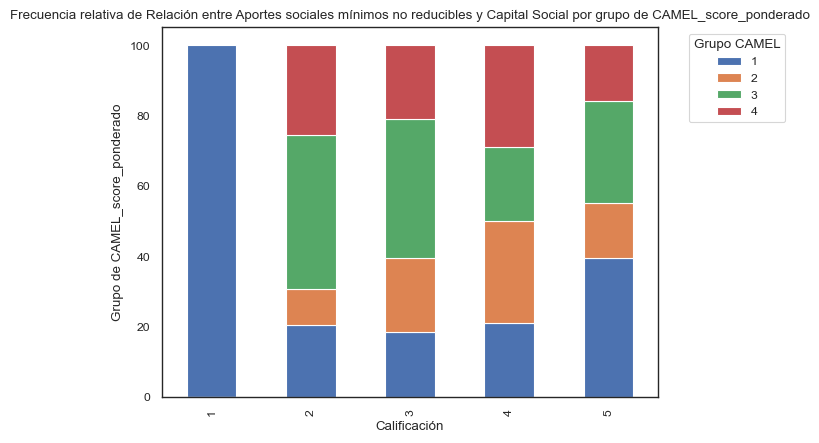

<Figure size 1000x500 with 0 Axes>

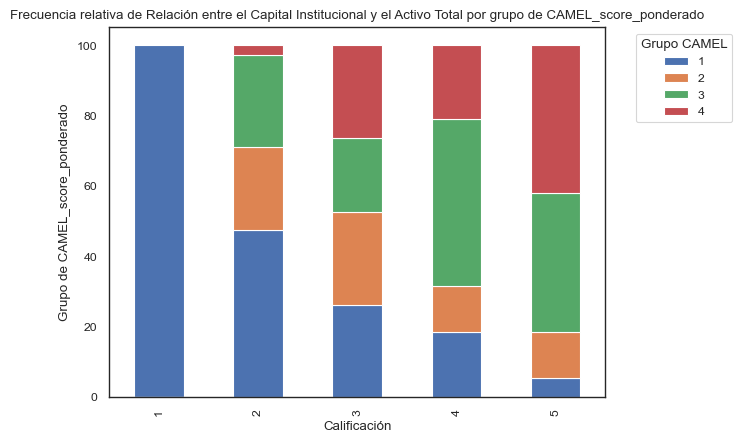

In [63]:
for indicador in indicadores:
    tabla_contingencia = 100*pd.crosstab(
        df[indicador],
        df['CAMEL_score_ponderado_grupos'],
        normalize='index'
    ).round(3)
    plt.figure(figsize=(10, 5))
    tabla_contingencia.plot(
        kind='bar', 
        stacked=True
        )
    plt.legend(title='Grupo CAMEL', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.title(f'Frecuencia relativa de {indicador} por grupo de CAMEL_score_ponderado')
    plt.xlabel('Calificación')
    plt.ylabel('Grupo de CAMEL_score_ponderado')
    plt.show();

In [64]:
# Tabla de contingencia de categoría de cooperativa y grupo de calificación por CAMEL_score_ponderado

categorias_grupo_camel = 100*pd.crosstab(
    df['Categoría'],
    df['CAMEL_score_ponderado_grupos'],
    #margins=True,
    normalize='index'
).round(3)

categorias_grupo_camel

CAMEL_score_ponderado_grupos,1,2,3,4
Categoría,,,,
Micro 1,23.5,17.6,35.3,23.5
Micro 2,39.1,21.7,26.1,13.0
Pequeñas,26.7,20.0,40.0,13.3
Medianas,34.8,13.6,30.3,21.2
Grandes,39.3,17.9,17.9,25.0
Megas,50.0,12.5,25.0,12.5


<Figure size 1000x500 with 0 Axes>

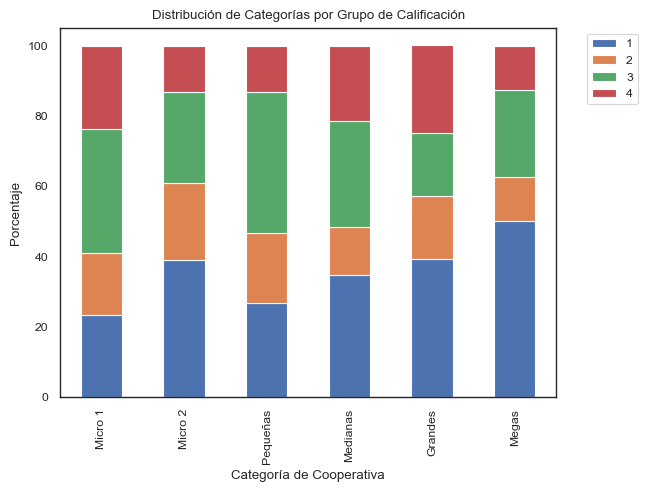

In [65]:
plt.figure(figsize=(10, 5))

categorias_grupo_camel.plot(
    kind='bar',
    stacked=True,
    legend=True,
    title='Distribución de Categorías por Grupo de Calificación'
);

# cambiar posición de la leyenda
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xlabel('Categoría de Cooperativa')
plt.ylabel('Porcentaje')
plt.show();

In [66]:
df.to_csv(data_dir / "Calificaciones_CAMEL_grupos.csv", index=False)

In [67]:
import numpy as np
from scipy.stats import chi2_contingency

tabla = pd.crosstab(
    df['Categoría'],
    df['CAMEL_score_ponderado_grupos']
    )

# 3. Cálculo de Chi-cuadrado y V de Cramér
chi2, p_val, dof, expected = chi2_contingency(tabla, correction=False)

n = df.shape[0]
r, c = tabla.shape

v_cramer = np.sqrt(chi2 / (n * min(r - 1, c - 1)))

print(f"Chi2: {chi2:.2f} | V de Cramer: {v_cramer:.4f} | p-value: {p_val:.4f}")

Chi2: 7.43 | V de Cramer: 0.1193 | p-value: 0.9446
